In [1]:

# Cell 1: Load the dataset

import pandas as pd
import matplotlib.pyplot as plt

# TODO 1: Set the path to your CSV inside data/raw/.
csv_path = "../data/raw/ai4i2020.csv"

# TODO 2: Load the CSV into a DataFrame named df.
df = pd.read_csv(csv_path)

# TODO 3: Display the first five rows.
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [2]:
df.shape


(10000, 14)

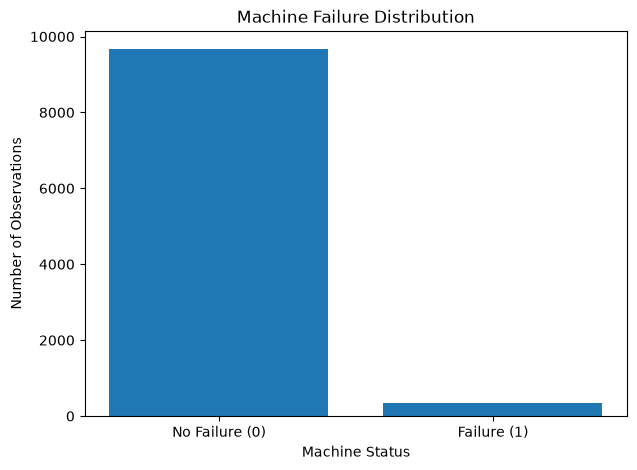

In [3]:
# Cell 3: Visualize machine failures

failure_counts = df["Machine failure"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(
    ["No Failure (0)", "Failure (1)"],
    failure_counts.values
)
plt.title("Machine Failure Distribution")
plt.xlabel("Machine Status")
plt.ylabel("Number of Observations")
plt.show()

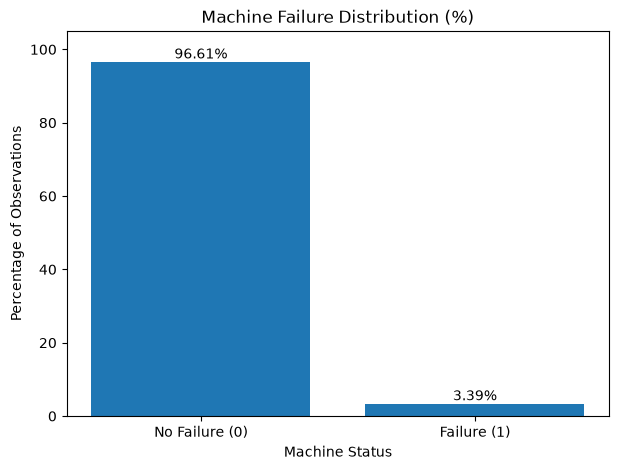

In [4]:
# Cell 4: Show failure percentages

failure_percentages = failure_counts / len(df) * 100

plt.figure(figsize=(7, 5))
bars = plt.bar(
    ["No Failure (0)", "Failure (1)"],
    failure_percentages.values
)

plt.bar_label(bars, fmt="%.2f%%")
plt.title("Machine Failure Distribution (%)")
plt.xlabel("Machine Status")
plt.ylabel("Percentage of Observations")
plt.ylim(0, 105)
plt.show()

In [5]:
# Cell 5: Separate features and target

features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df[features]
y = df["Machine failure"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (10000, 6)
Target shape: (10000,)


In [6]:
# Cell 6: Split the dataset

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print(X_train)

Training samples: 8000
Testing samples: 2000
     Type  Air temperature [K]  Process temperature [K]  \
4058    M                302.0                    310.9   
1221    M                297.0                    308.3   
6895    M                301.0                    311.6   
9863    L                298.9                    309.8   
8711    L                297.1                    308.5   
...   ...                  ...                      ...   
980     L                296.1                    306.7   
4266    L                302.7                    311.1   
7772    H                300.3                    311.5   
5780    L                301.7                    311.2   
1424    L                298.7                    309.7   

      Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  
4058                    1456         47.2               54  
1221                    1399         46.4              132  
6895                    1357         45.6              137  
98

In [7]:
# Cell 7: Preprocess data and train Random Forest

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

preprocessor = ColumnTransformer(
    transformers=[
        ("type", OneHotEncoder(handle_unknown="ignore"), ["Type"])
    ],
    remainder="passthrough"
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [8]:
# Cell 8: Evaluate model predictions

from sklearn.metrics import classification_report, confusion_matrix

y_pred = model.predict(X_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Confusion Matrix:
[[1917   15]
 [  22   46]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.75      0.68      0.71        68

    accuracy                           0.98      2000
   macro avg       0.87      0.83      0.85      2000
weighted avg       0.98      0.98      0.98      2000



In [11]:
# Cell 9: Compare against a majority-class baseline

from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

print("Baseline Results:")
print(classification_report(
    y_test,
    baseline_pred,
    zero_division=0
))


# Cell 10: Compare model performance

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

results = pd.DataFrame({
    "Model": ["Baseline", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, baseline_pred),
        accuracy_score(y_test, y_pred)
    ],
    "Failure Precision": [
        precision_score(y_test, baseline_pred, zero_division=0),
        precision_score(y_test, y_pred, zero_division=0)
    ],
    "Failure Recall": [
        recall_score(y_test, baseline_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0)
    ],
    "Failure F1": [
        f1_score(y_test, baseline_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ]
})

results.round(3)

Baseline Results:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



,Model,Accuracy,Failure Precision,Failure Recall,Failure F1
0,Baseline,0.966,0.000,0.000,0.000
1,Random Forest,0.982,0.754,0.676,0.713


In [12]:
# Cell 10: Compare models and save the trained model

import pandas as pd
import joblib
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from pathlib import Path

results = pd.DataFrame([
    {
        "Model": "Baseline",
        "Accuracy": accuracy_score(y_test, baseline_pred),
        "Failure Precision": precision_score(
            y_test, baseline_pred, zero_division=0
        ),
        "Failure Recall": recall_score(
            y_test, baseline_pred, zero_division=0
        ),
        "Failure F1": f1_score(
            y_test, baseline_pred, zero_division=0
        ),
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, y_pred),
        "Failure Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Failure Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "Failure F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
    },
])

display(results.round(3))

# Save the complete pipeline, including preprocessing
model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(model, model_dir / "predictive_maintenance.joblib")

print("Model saved successfully.")

,Model,Accuracy,Failure Precision,Failure Recall,Failure F1
0,Baseline,0.966,0.000,0.000,0.000
1,Random Forest,0.982,0.754,0.676,0.713


Model saved successfully.
